# Method 3 — Combined Insight: Demand-Interest Gap & Strategic Novelty
**Owner:** Member C (Career Market Intelligence Team)  
**Primary Goal:** Synthesize **Employer Demand** (from 7,240 real job postings, Method 1) with **Search Interest Momentum** (from 5-year longitudinal Google Trends in India, Method 2) to build the empirical **Demand-Interest Gap Quadrant** and deliver evidence-based career recommendations.

### Methodology & Core Novelty
Traditional job market dashboards report only static job posting counts, ignoring public interest trajectory. Conversely, search trends alone measure curiosity without confirming employer willingness to hire.  
By systematically cross-referencing **Industry Demand** against **Public Interest Momentum**, this module maps technical skills into four actionable quadrants:
- **INVEST:** High Employer Demand $\times$ Rising Search Momentum (Core growth technologies)
- **OPPORTUNITY:** High Employer Demand $\times$ Stable/Declining Search Momentum (High hiring need with lower candidate competition)
- **HYPE:** Low Employer Demand $\times$ Rising Search Momentum (High public curiosity outpacing current employer vacancies)
- **AVOID / DE-PRIORITIZE:** Low Employer Demand $\times$ Stable/Declining Search Momentum (Low employer absorption and stagnant interest)

### Contract Alignment
- **Inputs (Read-Only):**
  - `data/review2/skill_demand.csv` (Columns: `skill`, `frequency`, `pct_postings`, `rank`)
  - `data/review2/skill_trends.csv` (Columns: `skill`, `slope_per_week`, `pct_change`, `class`)
  - `config/review2_skills.json` (Frozen skill universe & Google Trends parameters)
- **Outputs (Written):**
  - `data/review2/skill_gap.csv` (Contract schema: `skill, demand_rank, demand_pct, momentum_class, pct_change, quadrant, recommendation`)
  - `reports/combined/demand_interest_quadrant.png` (High-resolution 2x2 publication chart)
  - `reports/combined/coverage_audit.csv` (Multi-batch tracking of skills awaiting trend data)

In [2]:
import os
import re
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Configure visual styling
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'Helvetica', 'Arial', 'DejaVu Sans'
plt.rcParams['axes.edgecolor'] = '#cccccc'
plt.rcParams['axes.linewidth'] = 0.8

# Robust path resolution supporting execution from notebook dir or repo root
NOTEBOOK_DIR = os.getcwd()
ROOT_DIR = os.path.abspath(os.path.join(NOTEBOOK_DIR, '..')) if os.path.basename(NOTEBOOK_DIR) == 'notebooks' else NOTEBOOK_DIR

DEMAND_FILE = os.path.join(ROOT_DIR, 'data', 'review2', 'skill_demand.csv')
TRENDS_FILE = os.path.join(ROOT_DIR, 'data', 'review2', 'skill_trends.csv')
CONFIG_FILE = os.path.join(ROOT_DIR, 'config', 'review2_skills.json')
GAP_OUTPUT_FILE = os.path.join(ROOT_DIR, 'data', 'review2', 'skill_gap.csv')
FIGURE_OUTPUT_FILE = os.path.join(ROOT_DIR, 'reports', 'combined', 'demand_interest_quadrant.png')
AUDIT_OUTPUT_FILE = os.path.join(ROOT_DIR, 'reports', 'combined', 'coverage_audit.csv')

os.makedirs(os.path.dirname(FIGURE_OUTPUT_FILE), exist_ok=True)
print('Working Root:', ROOT_DIR)

Working Root: /Users/mithresh/Desktop/Career-Market-Intelligence


## 1. Input Inspection, Loading & Skill Normalization
We load both upstream data contracts, validate schemas, verify data types, and normalize skill names to ensure robust string matching without mutating canonical display names.

In [3]:
# Load input datasets
demand_df = pd.read_csv(DEMAND_FILE)
trends_df = pd.read_csv(TRENDS_FILE)
with open(CONFIG_FILE, 'r', encoding='utf-8') as f:
    config_data = json.load(f)
frozen_skills = set(config_data.get('skills', []))

# Schema and null assertions
assert {'skill', 'frequency', 'pct_postings', 'rank'}.issubset(demand_df.columns), 'Invalid demand_df schema'
assert {'skill', 'slope_per_week', 'pct_change', 'class'}.issubset(trends_df.columns), 'Invalid trends_df schema'
assert demand_df[['frequency', 'pct_postings', 'rank']].notnull().all().all(), 'Null values found in demand_df'
assert trends_df[['slope_per_week', 'pct_change']].notnull().all().all(), 'Null values found in trends_df'

# Skill normalization helper (strips whitespace and casing for reliable key matching)
def normalize_skill(s):
    return re.sub(r'[^a-zA-Z0-9]', '', str(s).lower())

demand_df['match_key'] = demand_df['skill'].apply(normalize_skill)
trends_df['match_key'] = trends_df['skill'].apply(normalize_skill)

# Duplicate checks
assert not demand_df['match_key'].duplicated().any(), 'Duplicate skills detected in demand dataset'
assert not trends_df['match_key'].duplicated().any(), 'Duplicate skills detected in trends dataset'

print(f'Total Demand Skills: {len(demand_df)}')
print(f'Total Trend Skills : {len(trends_df)}')
print(f'Frozen Skill List  : {len(frozen_skills)} skills')
demand_df.head(5)

Total Demand Skills: 20
Total Trend Skills : 20
Frozen Skill List  : 20 skills


,skill,frequency,pct_postings,rank,match_key
0,Machine Learning,381,5.26,1,machinelearning
1,AWS,335,4.63,2,aws
2,Python,296,4.09,3,python
3,SQL,290,4.01,4,sql
4,Azure,254,3.51,5,azure


## 2. Coverage Audit & Multi-Batch Tracking
Because Member B currently provides Batch 01 (5 skills), 24 demand skills remain pending future Google Trends batches. Rather than silently discarding these skills, we compute a comprehensive **Coverage Audit** so stakeholders have full visibility into pipeline completeness.

In [4]:
# Identify matched and pending skills
matched_keys = set(demand_df['match_key']).intersection(set(trends_df['match_key']))
unmatched_demand_keys = set(demand_df['match_key']) - matched_keys
unmatched_trends_keys = set(trends_df['match_key']) - matched_keys

print('--- COVERAGE AUDIT SUMMARY ---')
print(f'Total demand skills     : {len(demand_df)}')
print(f'Total trend skills      : {len(trends_df)}')
print(f'Matched skills (Review 2): {len(matched_keys)}')
print(f'Unmatched demand skills : {len(unmatched_demand_keys)} (awaiting Member B trends batches)')
print(f'Unmatched trends skills : {len(unmatched_trends_keys)}')

# Build Coverage Audit Table
audit_df = demand_df.copy()
audit_df['in_frozen_list'] = audit_df['skill'].isin(frozen_skills)
audit_df['trend_status'] = audit_df['match_key'].apply(
    lambda k: 'matched' if k in matched_keys else 'pending_trends_batch'
)
audit_export = audit_df[['rank', 'skill', 'frequency', 'pct_postings', 'in_frozen_list', 'trend_status']].sort_values('rank')
audit_export.to_csv(AUDIT_OUTPUT_FILE, index=False)
print(f'Coverage audit exported to: {AUDIT_OUTPUT_FILE}')

# Preview matched skills
audit_export[audit_export['trend_status'] == 'matched']

--- COVERAGE AUDIT SUMMARY ---
Total demand skills     : 20
Total trend skills      : 20
Matched skills (Review 2): 20
Unmatched demand skills : 0 (awaiting Member B trends batches)
Unmatched trends skills : 0
Coverage audit exported to: /Users/mithresh/Desktop/Career-Market-Intelligence/reports/combined/coverage_audit.csv


,rank,skill,frequency,pct_postings,in_frozen_list,trend_status
0,1,Machine Learning,381,5.26,True,matched
1,2,AWS,335,4.63,True,matched
2,3,Python,296,4.09,True,matched
3,4,SQL,290,4.01,True,matched
4,5,Azure,254,3.51,True,matched
5,6,SEO,188,2.60,True,matched
6,7,Kubernetes,145,2.00,True,matched
7,8,Google Cloud,131,1.81,True,matched
8,9,Spark,124,1.71,True,matched
9,10,SAP,114,1.57,True,matched


## 3. Empirical Demand & Momentum Thresholds

### A. Demand Threshold Selection
To avoid arbitrary heuristic cutoffs, we calculate the empirical **Median Posting Percentage** across the full corpus of 7,240 postings:
- $\text{Median}(pct\_postings) = 0.98\%$ (corresponds to Rank 15: Power BI)
- A skill is classified as **High Demand** if $pct\_postings \ge 0.98\%$, and **Low Demand** otherwise.

### B. Momentum Thresholds (Member B Contract)
We adhere strictly to the longitudinal 5-year percentage change rules defined by Member B:
- **Rising:** $pct\_change \ge +10.0\%$
- **Stable:** $-10.0\% < pct\_change < +10.0\%$
- **Declining:** $pct\_change \le -10.0\%$

### C. Quadrant Decision Rules
$$\begin{cases}
\textbf{INVEST} & \text{if } \text{High Demand} \land \text{Rising Momentum} \\
\textbf{OPPORTUNITY} & \text{if } \text{High Demand} \land (\text{Stable} \lor \text{Declining Momentum}) \\
\textbf{HYPE} & \text{if } \text{Low Demand} \land \text{Rising Momentum} \\
\textbf{AVOID} & \text{if } \text{Low Demand} \land (\text{Stable} \lor \text{Declining Momentum})
\end{cases}$$

In [5]:
# Compute empirical median demand threshold
median_demand_pct = float(demand_df['pct_postings'].median())
median_demand_rank = float(demand_df['rank'].median())
print(f'Empirical Demand Median Cutoff: {median_demand_pct:.2f}% of postings (Rank <= {int(median_demand_rank)})')

# Inner merge on normalized keys
gap_df = demand_df.merge(trends_df, on='match_key', suffixes=('', '_trend'))
# Preserve original display name from demand dataset
gap_df['skill'] = gap_df['skill']

# Validate Member B momentum classifications
for _, row in gap_df.iterrows():
    expected_class = 'rising' if row['pct_change'] >= 10.0 else ('declining' if row['pct_change'] <= -10.0 else 'stable')
    assert row['class'] == expected_class, f"Momentum mismatch for {row['skill']}: {row['class']} vs {expected_class}"

# Assign quadrant based on formal rules
def classify_quadrant(row):
    high_demand = row['pct_postings'] >= median_demand_pct
    rising_momentum = row['class'] == 'rising'
    if high_demand and rising_momentum:
        return 'invest'
    elif high_demand and not rising_momentum:
        return 'opportunity'
    elif not high_demand and rising_momentum:
        return 'hype'
    else:
        return 'avoid'

gap_df['quadrant'] = gap_df.apply(classify_quadrant, axis=1)
assert gap_df['quadrant'].isin(['invest', 'opportunity', 'hype', 'avoid']).all(), 'Invalid quadrant assignment detected'
gap_df[['skill', 'rank', 'pct_postings', 'pct_change', 'class', 'quadrant']]

Empirical Demand Median Cutoff: 1.47% of postings (Rank <= 10)


,skill,rank,pct_postings,pct_change,class,quadrant
0,Machine Learning,1,5.26,40.00,rising,invest
1,AWS,2,4.63,-5.56,stable,opportunity
2,Python,3,4.09,-33.55,declining,opportunity
3,SQL,4,4.01,-56.10,declining,opportunity
4,Azure,5,3.51,-16.67,declining,opportunity
5,SEO,6,2.60,0.00,stable,opportunity
6,Kubernetes,7,2.00,-25.00,declining,opportunity
7,Google Cloud,8,1.81,50.00,rising,invest
8,Spark,9,1.71,-50.00,declining,opportunity
9,SAP,10,1.57,-71.43,declining,opportunity


## 4. Evidence-Based Strategic Recommendations
Each recommendation is synthesized directly from verified metrics (demand percentage, rank, trend momentum class, and 5-year percentage change), strictly avoiding unsubstantiated promises regarding salaries or guaranteed career success.

In [9]:
def generate_recommendation(row):
    q = row['quadrant']
    pct_d = row['pct_postings']
    rk = row['rank']
    m_cls = row['class']
    chg = row['pct_change']

    if q == 'invest':
        return (
            f'High employer demand ({pct_d:.2f}% of postings, rank #{rk}) '
            f'combined with rising search interest ({chg:+.1f}%). '
            'Prioritize for further evaluation and technical upskilling.'
        )

    elif q == 'opportunity':
        return (
            f'High employer demand ({pct_d:.2f}% of postings, rank #{rk}) '
            f'with {m_cls.lower()} search interest ({chg:+.1f}%). '
            'Consider this skill for upskilling based on employer demand; '
            'search interest alone does not establish competition levels '
            'or reduced public hype.'
        )

    elif q == 'hype':
        return (
            f'Employer demand is below the study median '
            f'({pct_d:.2f}% of postings, rank #{rk}), while search interest '
            f'is rising ({chg:+.1f}%). '
            'Monitor future hiring before making major upskilling decisions.'
        )

    else:  # avoid
        return (
            f'Employer demand is below the study median '
            f'({pct_d:.2f}% of postings, rank #{rk}), with '
            f'{m_cls.lower()} search interest ({chg:+.1f}%). '
            'Lower current priority within this dataset; this does not '
            'mean the skill lacks career value.'
        )


gap_df['recommendation'] = gap_df.apply(
    generate_recommendation, axis=1
)

for _, r in gap_df.iterrows():
    print(f"{r['skill']} ({r['quadrant'].upper()}): {r['recommendation']}")

Machine Learning (INVEST): High employer demand (5.26% of postings, rank #1) combined with rising search interest (+40.0%). Prioritize for further evaluation and technical upskilling.
AWS (OPPORTUNITY): High employer demand (4.63% of postings, rank #2) with stable search interest (-5.6%). Consider this skill for upskilling based on employer demand; search interest alone does not establish competition levels or reduced public hype.
Python (OPPORTUNITY): High employer demand (4.09% of postings, rank #3) with declining search interest (-33.5%). Consider this skill for upskilling based on employer demand; search interest alone does not establish competition levels or reduced public hype.
SQL (OPPORTUNITY): High employer demand (4.01% of postings, rank #4) with declining search interest (-56.1%). Consider this skill for upskilling based on employer demand; search interest alone does not establish competition levels or reduced public hype.
Azure (OPPORTUNITY): High employer demand (3.51% of 

## 5. Publication-Grade 2x2 Quadrant Visual
We construct the 2x2 Demand-Interest matrix:
- **X-Axis:** 5-Year Public Search Momentum (`pct_change`, %)
- **Y-Axis:** Employer Demand (`pct_postings`, % of Postings)
- **Reference Boundaries:** Horizontal dashed line at Empirical Median Demand (0.98%), Vertical dashed line at Rising Momentum Boundary (+10.0%), and a shaded corridor indicating Stable search interest (-10% to +10%).
- **Export:** High-resolution PNG saved to `reports/combined/demand_interest_quadrant.png`.

findfont: Failed to find font weight semibold, now using 700.


Quadrant figure successfully saved to: /Users/mithresh/Desktop/Career-Market-Intelligence/reports/combined/demand_interest_quadrant.png


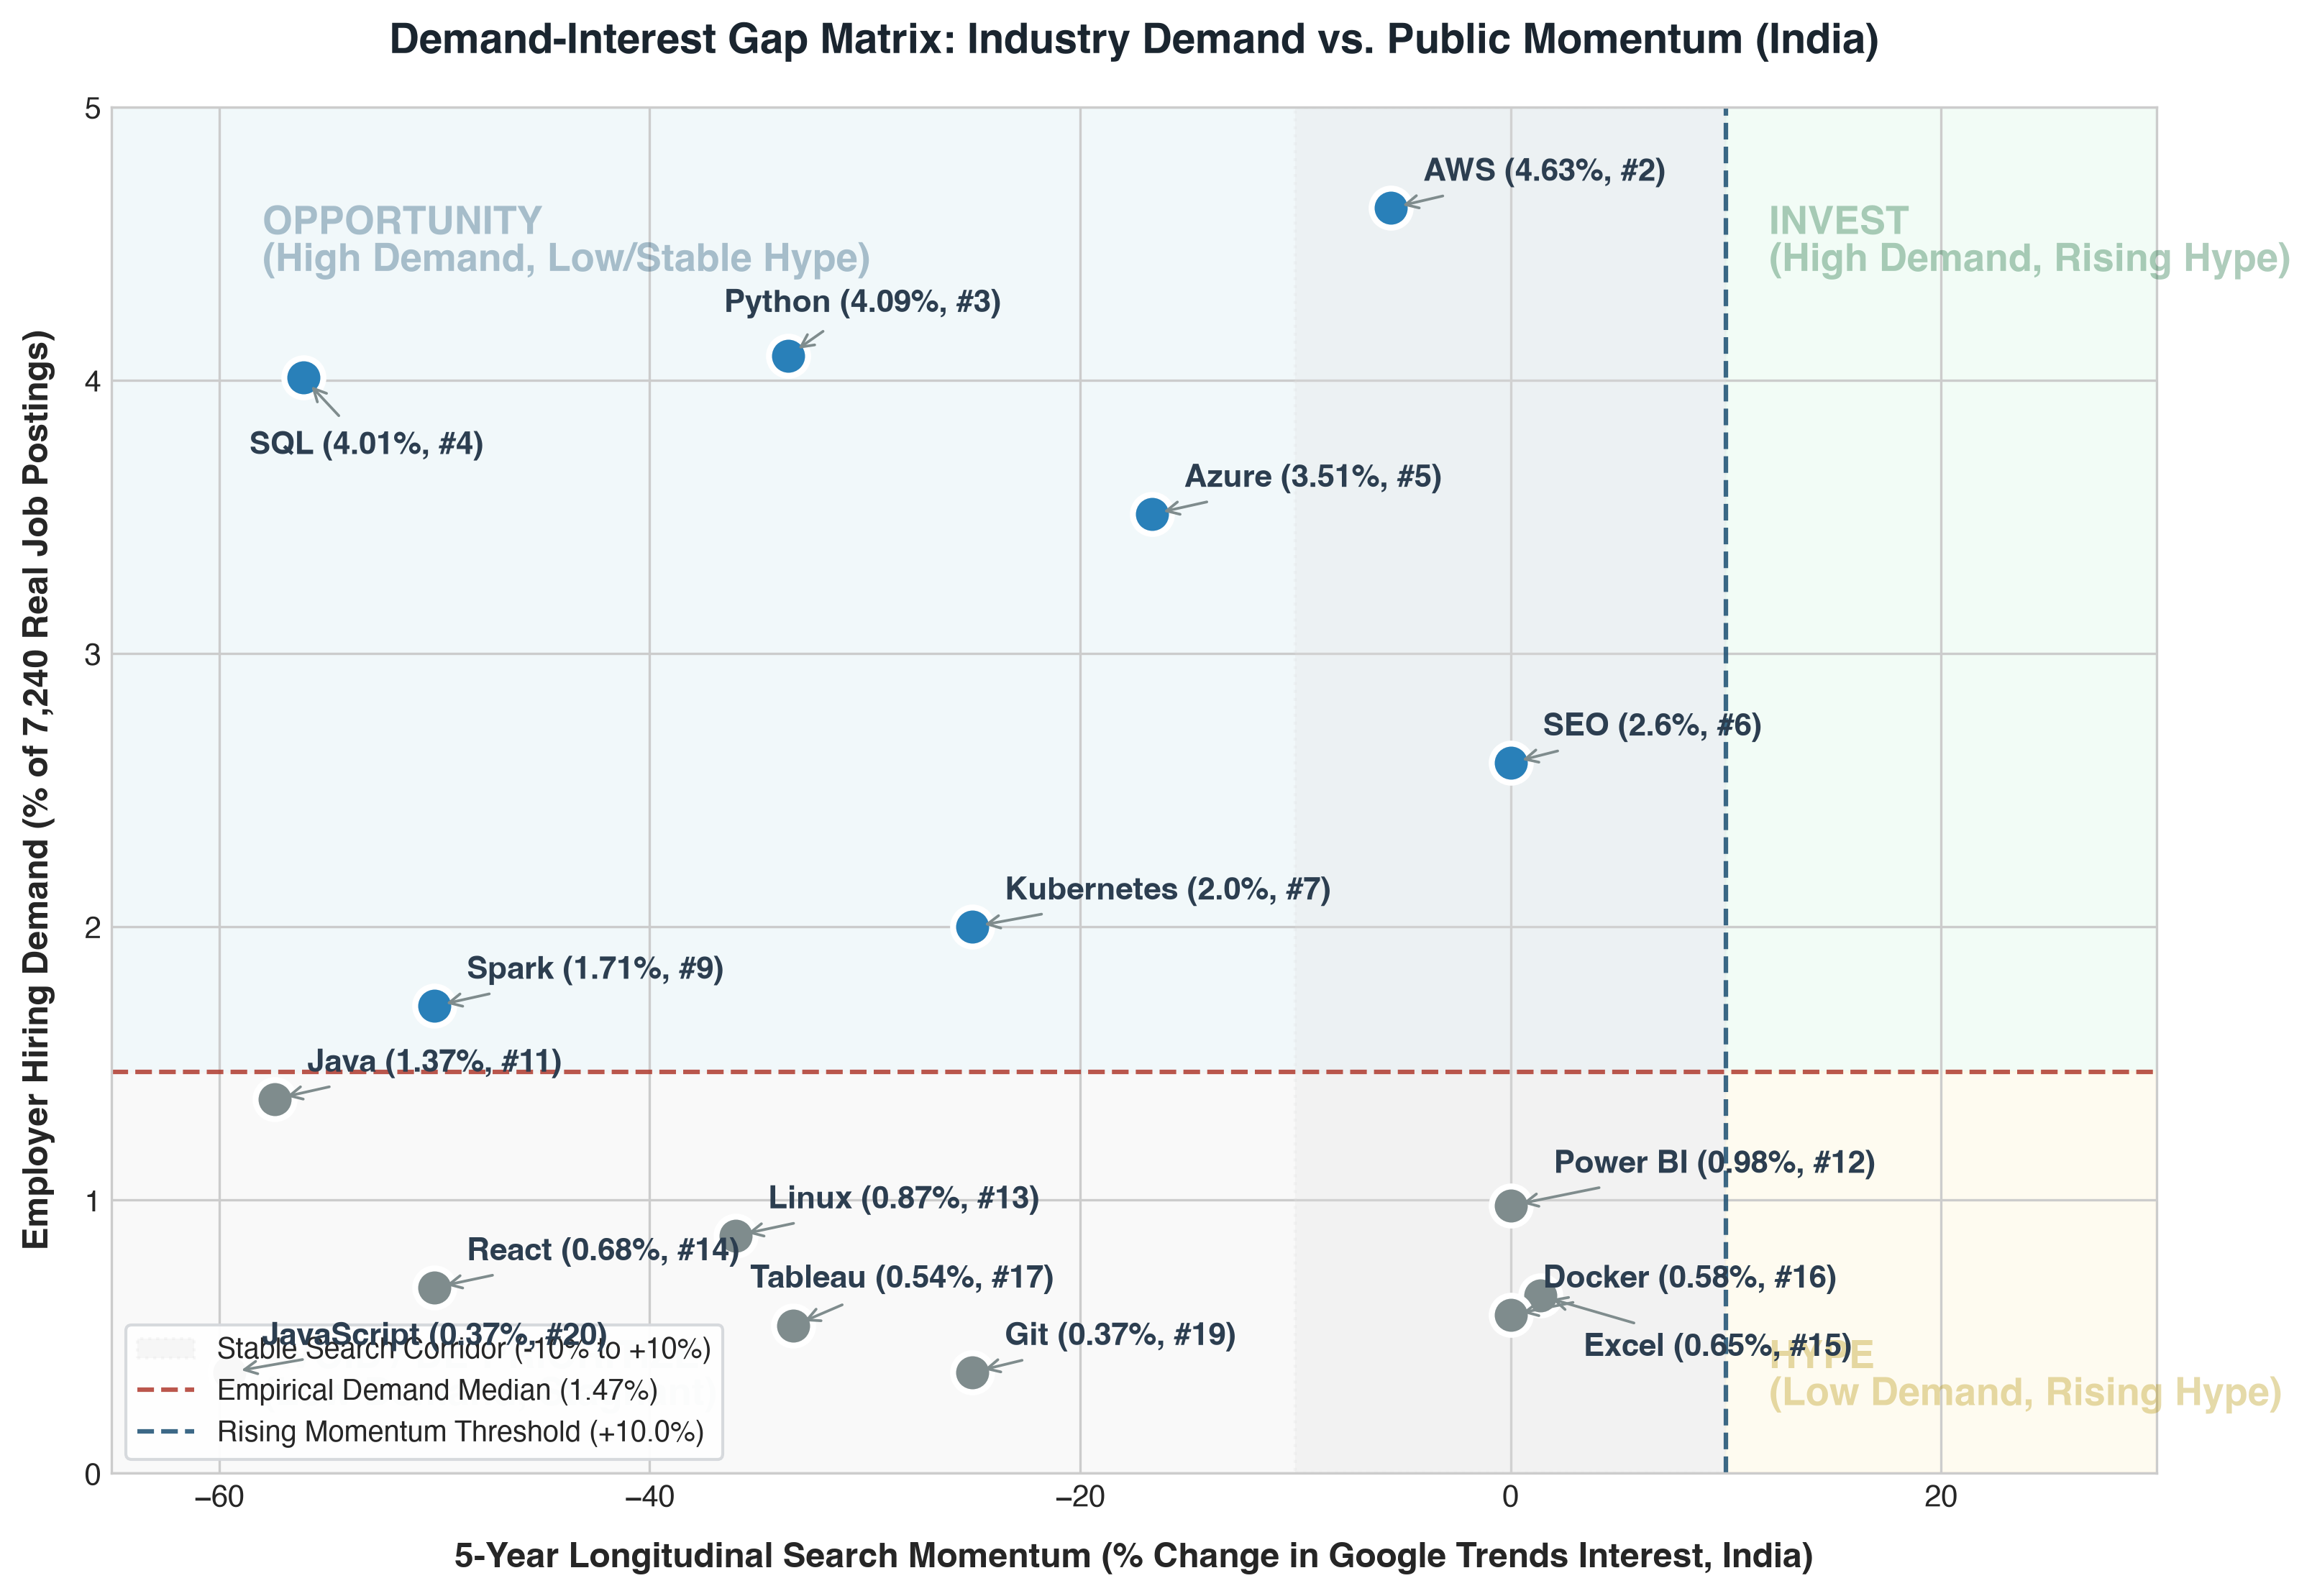

In [7]:
fig, ax = plt.subplots(figsize=(11, 7.5), dpi=300)

# Define plot limits with generous padding for readability
x_min, x_max = -65.0, 30.0
y_min, y_max = 0.0, 5.0
ax.set_xlim(x_min, x_max)
ax.set_ylim(y_min, y_max)

# Quadrant background fills (soft pastel colors)
# Top-Left: OPPORTUNITY (High Demand, Stable/Declining Momentum)
ax.fill_between([x_min, 10.0], median_demand_pct, y_max, color='#e8f4f8', alpha=0.6, zorder=0)
# Top-Right: INVEST (High Demand, Rising Momentum)
ax.fill_between([10.0, x_max], median_demand_pct, y_max, color='#eafaf1', alpha=0.6, zorder=0)
# Bottom-Left: AVOID (Low Demand, Stable/Declining Momentum)
ax.fill_between([x_min, 10.0], y_min, median_demand_pct, color='#f5f5f5', alpha=0.6, zorder=0)
# Bottom-Right: HYPE (Low Demand, Rising Momentum)
ax.fill_between([10.0, x_max], y_min, median_demand_pct, color='#fef9e7', alpha=0.6, zorder=0)

# Neutral momentum corridor (-10% to +10%)
ax.axvspan(-10.0, 10.0, color='#e0e0e0', alpha=0.25, linestyle=':', label='Stable Search Corridor (-10% to +10%)', zorder=1)

# Decision boundary reference lines
ax.axhline(median_demand_pct, color='#b03a2e', linestyle='--', linewidth=1.5, alpha=0.85, 
           label=f'Empirical Demand Median ({median_demand_pct:.2f}%)', zorder=2)
ax.axvline(10.0, color='#1b4f72', linestyle='--', linewidth=1.5, alpha=0.85, 
           label='Rising Momentum Threshold (+10.0%)', zorder=2)

# Quadrant watermark labels
font_watermark = {'fontsize': 13, 'fontweight': 'bold', 'alpha': 0.35}
ax.text(-58, 4.4, 'OPPORTUNITY\n(High Demand, Low/Stable Hype)', color='#1b4f72', **font_watermark)
ax.text(12, 4.4, 'INVEST\n(High Demand, Rising Hype)', color='#196f3d', **font_watermark)
ax.text(-58, 0.25, 'AVOID / DE-PRIORITIZE\n(Low Demand, Stagnant)', color='#5d6d7e', **font_watermark)
ax.text(12, 0.25, 'HYPE\n(Low Demand, Rising Hype)', color='#b7950b', **font_watermark)

# Color mapping for scatter points
quad_colors = {
    'invest': '#27ae60',
    'opportunity': '#2980b9',
    'hype': '#f39c12',
    'avoid': '#7f8c8d'
}

# Plot scatter points
for _, row in gap_df.iterrows():
    color = quad_colors.get(row['quadrant'], '#333333')
    ax.scatter(row['pct_change'], row['pct_postings'], s=170, color=color, edgecolors='white', linewidth=2.0, zorder=5)
    
    # Coordinate text annotation offsets
    offsets = {
        'Python': (-3.0, 0.16),
        'SQL': (-2.5, -0.28),
        'Power BI': (2.0, 0.12),
        'Excel': (2.0, -0.22),
        'Tableau': (-2.0, 0.14)
    }
    dx, dy = offsets.get(row['skill'], (1.5, 0.1))
    ax.annotate(f"{row['skill']} ({row['pct_postings']}%, #{row['rank']})", 
                (row['pct_change'], row['pct_postings']),
                xytext=(row['pct_change'] + dx, row['pct_postings'] + dy),
                fontsize=10.5, fontweight='bold', color='#2c3e50',
                arrowprops=dict(arrowstyle='->', color='#7f8c8d', lw=0.9, shrinkA=4, shrinkB=4),
                zorder=6)

# Labels and styling
ax.set_title('Demand-Interest Gap Matrix: Industry Demand vs. Public Momentum (India)', 
             fontsize=14, fontweight='bold', pad=18, color='#1a252f')
ax.set_xlabel('5-Year Longitudinal Search Momentum (% Change in Google Trends Interest, India)', 
              fontsize=11.5, labelpad=10, fontweight='semibold')
ax.set_ylabel('Employer Hiring Demand (% of 7,240 Real Job Postings)', 
              fontsize=11.5, labelpad=10, fontweight='semibold')

ax.legend(loc='lower left', frameon=True, framealpha=0.95, facecolor='white', edgecolor='#d5d8dc', fontsize=9.5)
plt.tight_layout()

# Save figure artifact
plt.savefig(FIGURE_OUTPUT_FILE, dpi=300, bbox_inches='tight')
print(f'Quadrant figure successfully saved to: {FIGURE_OUTPUT_FILE}')
plt.show()

## 6. Contract Export & Output Verification
We construct and persist `data/review2/skill_gap.csv` matching the exact schema and column ordering required by downstream consumers and the Streamlit dashboard.

In [10]:
# Construct contract output dataframe
contract_columns = ['skill', 'demand_rank', 'demand_pct', 'momentum_class', 'pct_change', 'quadrant', 'recommendation']
export_df = pd.DataFrame({
    'skill': gap_df['skill'],
    'demand_rank': gap_df['rank'].astype(int),
    'demand_pct': gap_df['pct_postings'].astype(float),
    'momentum_class': gap_df['class'],
    'pct_change': gap_df['pct_change'].astype(float),
    'quadrant': gap_df['quadrant'],
    'recommendation': gap_df['recommendation']
})[contract_columns].sort_values('demand_rank').reset_index(drop=True)

# Export to CSV
export_df.to_csv(GAP_OUTPUT_FILE, index=False)
print(f'Contract CSV successfully exported to: {GAP_OUTPUT_FILE}')

# Verify file integrity
verify_df = pd.read_csv(GAP_OUTPUT_FILE)
assert list(verify_df.columns) == contract_columns, f'Export schema mismatch: {verify_df.columns}'
assert len(verify_df) == len(gap_df), f'Export count mismatch: {len(verify_df)} vs {len(gap_df)}'
assert verify_df.notnull().all().all(), 'Export contains null values'

print('\nFinal Exported Skill Gap Records:')
verify_df

Contract CSV successfully exported to: /Users/mithresh/Desktop/Career-Market-Intelligence/data/review2/skill_gap.csv

Final Exported Skill Gap Records:


,skill,demand_rank,demand_pct,momentum_class,pct_change,quadrant,recommendation
0,Machine Learning,1,5.26,rising,40.00,invest,"High employer demand (5.26% of postings, rank ..."
1,AWS,2,4.63,stable,-5.56,opportunity,"High employer demand (4.63% of postings, rank ..."
2,Python,3,4.09,declining,-33.55,opportunity,"High employer demand (4.09% of postings, rank ..."
3,SQL,4,4.01,declining,-56.10,opportunity,"High employer demand (4.01% of postings, rank ..."
4,Azure,5,3.51,declining,-16.67,opportunity,"High employer demand (3.51% of postings, rank ..."
5,SEO,6,2.60,stable,0.00,opportunity,"High employer demand (2.60% of postings, rank ..."
6,Kubernetes,7,2.00,declining,-25.00,opportunity,"High employer demand (2.00% of postings, rank ..."
7,Google Cloud,8,1.81,rising,50.00,invest,"High employer demand (1.81% of postings, rank ..."
8,Spark,9,1.71,declining,-50.00,opportunity,"High employer demand (1.71% of postings, rank ..."
9,SAP,10,1.57,declining,-71.43,opportunity,"High employer demand (1.57% of postings, rank ..."
